In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import yaml
from typing import Optional
from matplotlib.lines import Line2D

In [2]:
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

In [3]:
with open("OkabeIto.yaml", "r") as fp:
    OkabeIto = yaml.safe_load(fp)

In [4]:
directory = "../output/null_model"
output_dir = "../figures"

In [5]:
def plot_single(
    df: pd.DataFrame,
    axes: Optional[plt.Axes] = None,
    figsize: tuple[int, int] = (5, 5),
    variable: str = "pi",
    color: Optional[str] = None
) -> tuple[plt.Figure, plt.Axes]:
    if axes:
        ax = axes
        fig = axes.get_figure()
    else:
        fig, ax = plt.subplots(figsize=figsize)

    sns.lineplot(
        x="res",
        y=variable,
        data=df[["res", "network", variable]],
        color=color,
        linewidth=2.5,
        ax=ax
    )
    ax.set_xlabel("Resolution")
    ax.set_ylabel("$\Pi$")

    if axes is None:
        return fig, ax


def plot(q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods):
    fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
    plot_single(q_road1, axs[0][0], color=OkabeIto["orange"])
    axs[0][0].set_title("Primary roads")
    plot_single(q_road2, axs[1][0], color=OkabeIto["skyblue"])
    axs[1][0].set_title("Secondary roads")
    plot_single(q_railways, axs[0][2], color=OkabeIto["vermilion"])
    axs[0][2].set_title("Railways")
    plot_single(q_river, axs[1][2], color=OkabeIto["bluishgreen"])
    axs[1][2].set_title("River")
    plot_single(q_districts, axs[0][1], color=OkabeIto["blue"])
    axs[0][1].set_title("Districts")
    plot_single(q_neighborhoods, axs[1][1], color=OkabeIto["yellow"])
    axs[1][1].set_title("Neighborhoods")
    # fig.savefig("figures/null_model.png",
    #             dpi=120, facecolor="white", bbox_inches="tight")
    inputs = [q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods]
    max_ = max([i["pi"].max() for i in inputs])*1.1
    min_ = min([i["pi"].min() for i in inputs])*0.9
    axs[0][0].set_ylim([min_, max_])
    axs[0][1].set_ylim([min_, max_])
    axs[0][2].set_ylim([min_, max_])
    axs[1][0].set_ylim([min_, max_])
    axs[1][1].set_ylim([min_, max_])
    axs[1][2].set_ylim([min_, max_])
    return fig

def plot2(q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods, variable: str = "pi"):
    fig, ax = plt.subplots(figsize=(8, 8))
    plot_single(q_road1, ax, color=OkabeIto["orange"], variable=variable)
    plot_single(q_road2, ax, color=OkabeIto["skyblue"], variable=variable)
    plot_single(q_railways, ax, color=OkabeIto["vermilion"], variable=variable)
    plot_single(q_river, ax, color=OkabeIto["bluishgreen"], variable=variable)
    plot_single(q_districts, ax, color=OkabeIto["blue"], variable=variable)
    plot_single(q_neighborhoods, ax, color=OkabeIto["yellow"], variable=variable)

    inputs = [q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods]
    max_ = max([i[variable].max() for i in inputs])*1.1
    min_ = min([i[variable].min() for i in inputs])*0.9
    ax.set_ylim([min_, max_])

    labels = ["Districts", "Neighborhoods", "Primary roads", "Secondary roads", "River", "Railways"]
    colors = [OkabeIto["blue"], OkabeIto["yellow"], OkabeIto["orange"],
              OkabeIto["skyblue"], OkabeIto["bluishgreen"], OkabeIto["vermilion"]]
    elements = []
    for co, la in zip(colors, labels):
        elem = Line2D([0], [0], color=co, lw=4, linestyle="solid", label=la)
        elements.append(elem)
    ax.legend(handles=elements, ncols=3)
    return fig, ax

In [ ]:
q_road1 = pd.read_csv(f"{directory}/q_road1.csv")
q_road2 = pd.read_csv(f"{directory}/q_road2.csv")
q_railways = pd.read_csv(f"{directory}/q_railways.csv")
q_river = pd.read_csv(f"{directory}/q_river.csv")
q_districts = pd.read_csv(f"{directory}/q_districts.csv")
q_neighborhoods = pd.read_csv(f"{directory}/q_neighborhoods.csv")

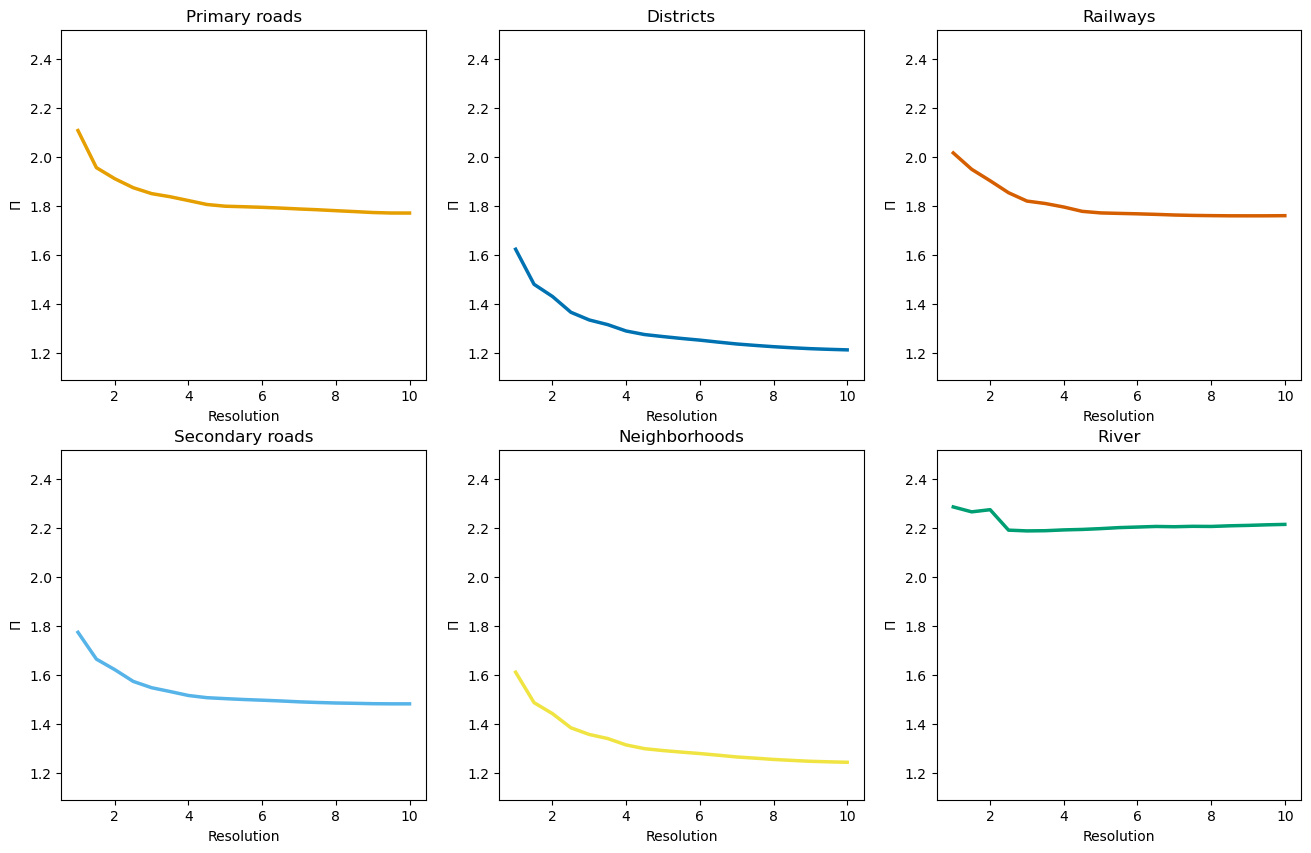

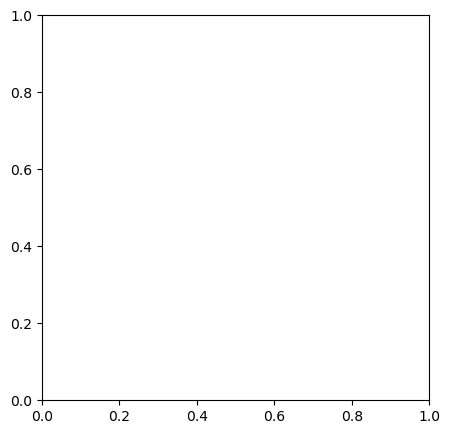

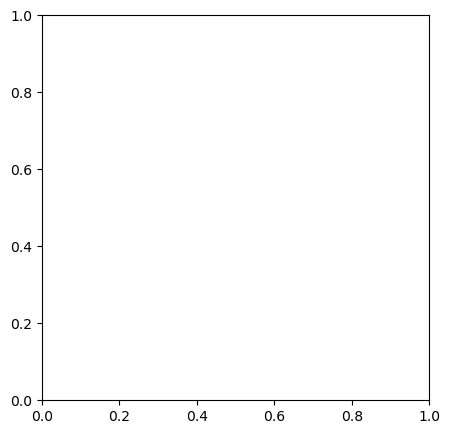

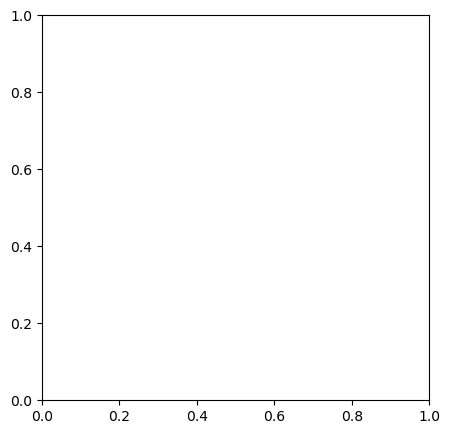

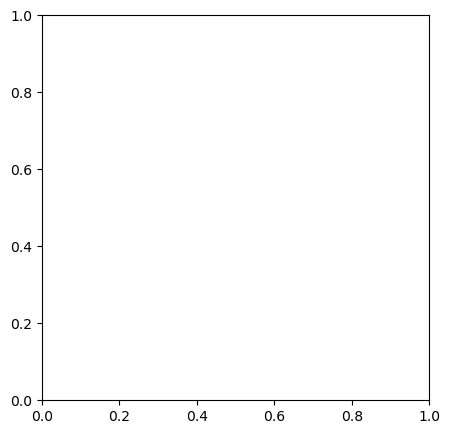

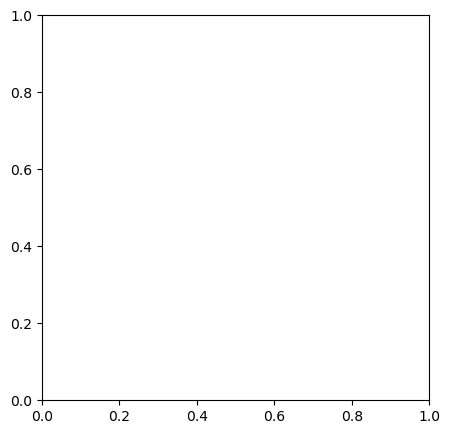

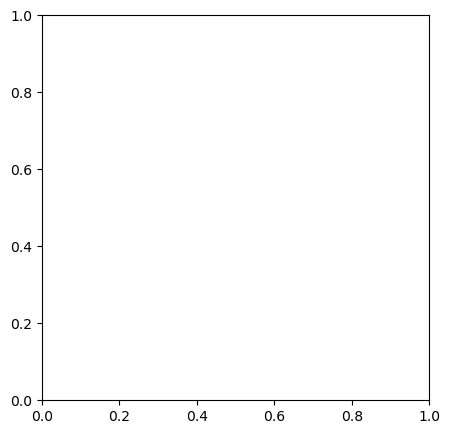

In [7]:
f = plot(q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods)
# f.savefig(f"{output_dir}/null_model.png",
#           dpi=300, facecolor="white", bbox_inches="tight")

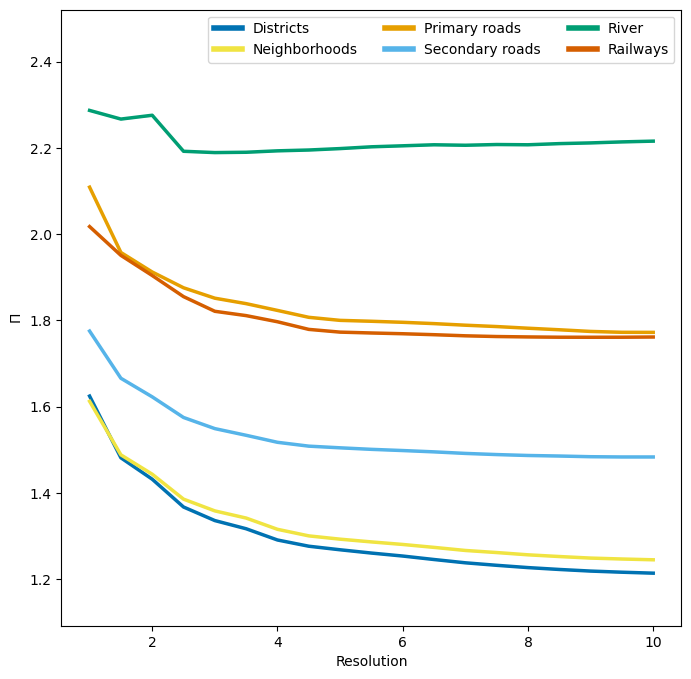

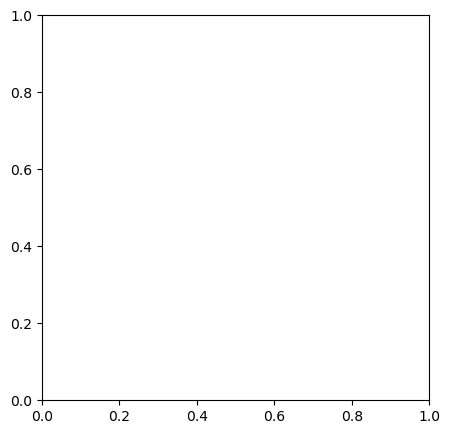

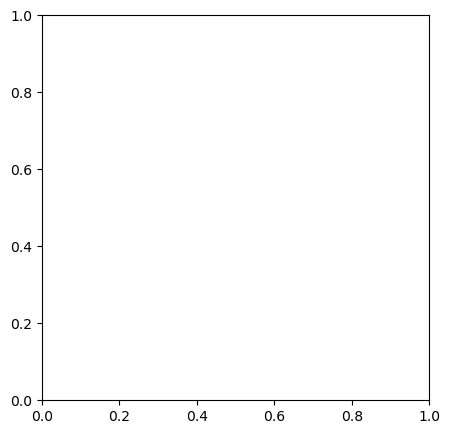

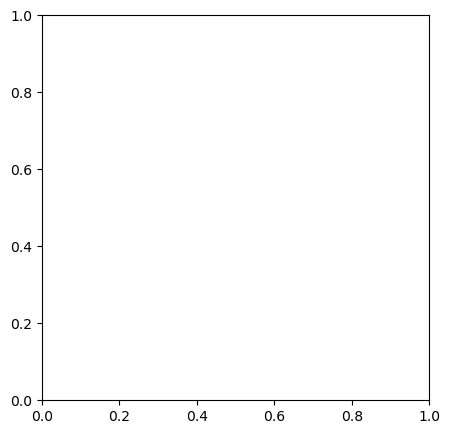

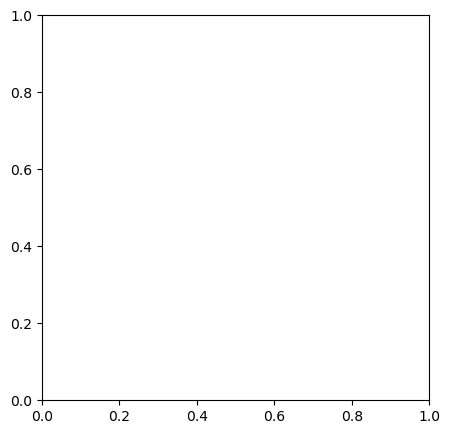

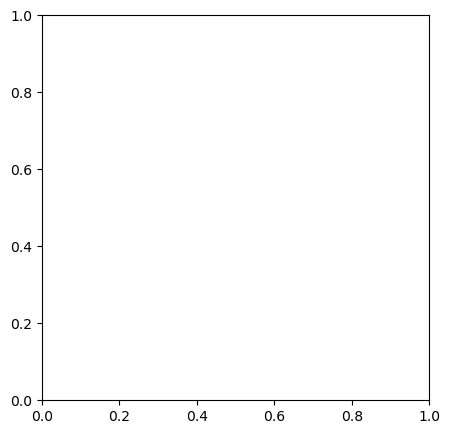

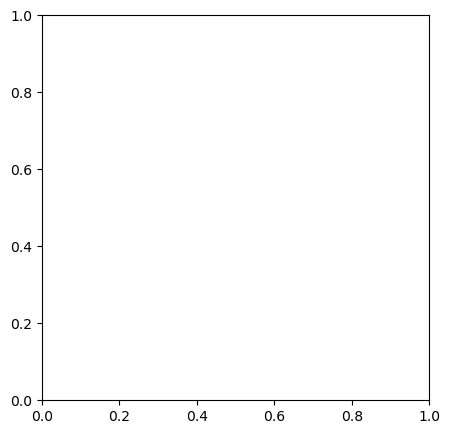

In [8]:
f, a = plot2(q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods)
for i in ["png", "pdf", "svg"]:
    f.savefig(f"{output_dir}/null_model_combined.{i}",
              dpi=300, facecolor="white", bbox_inches="tight")

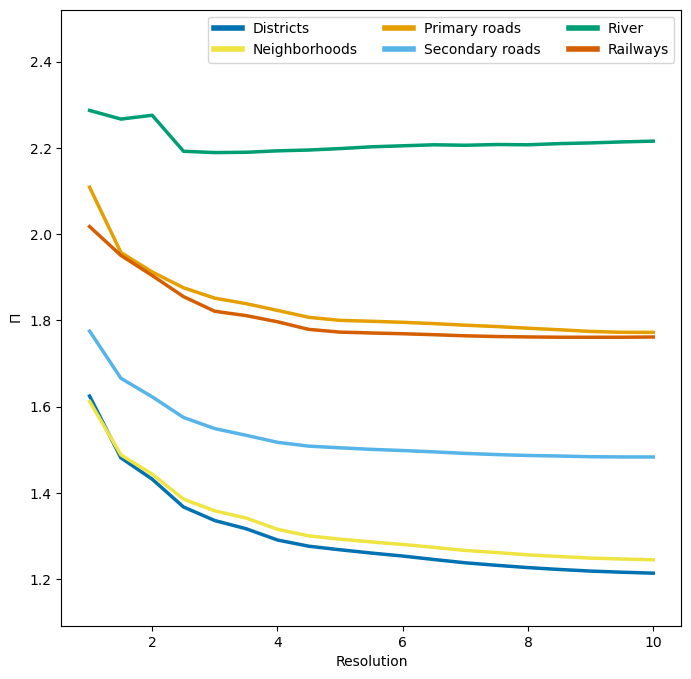

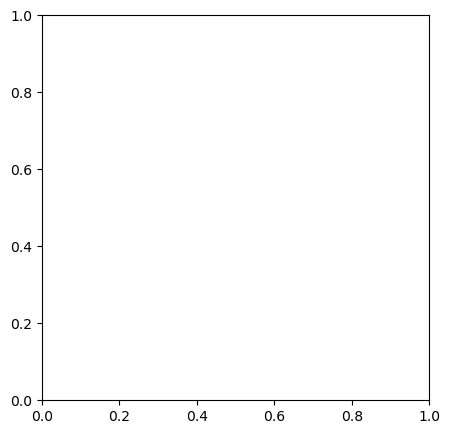

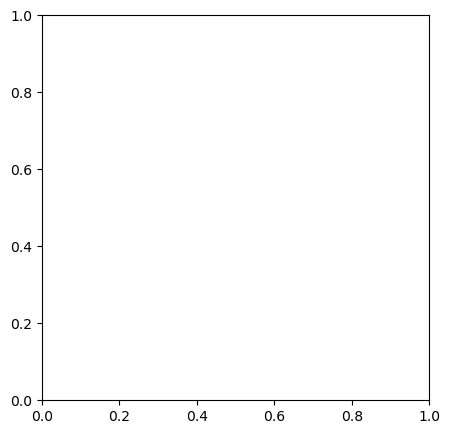

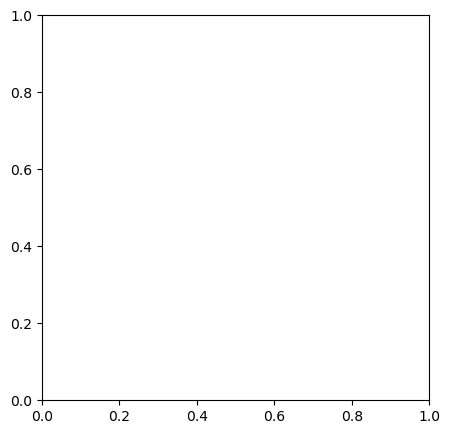

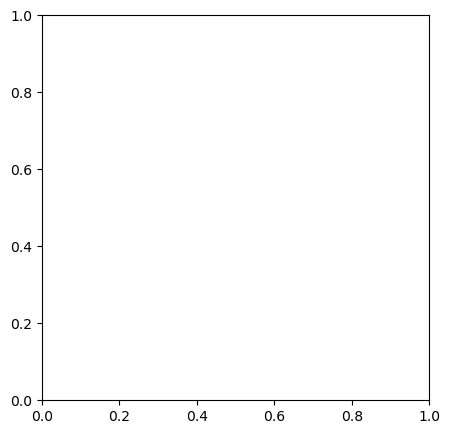

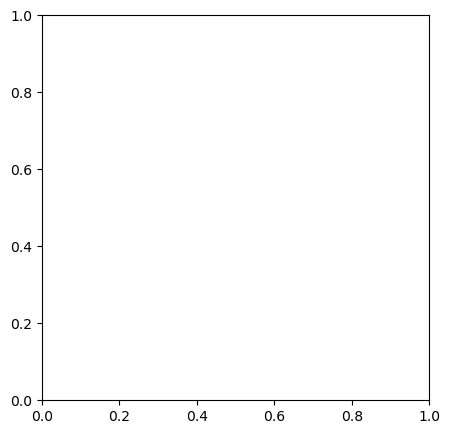

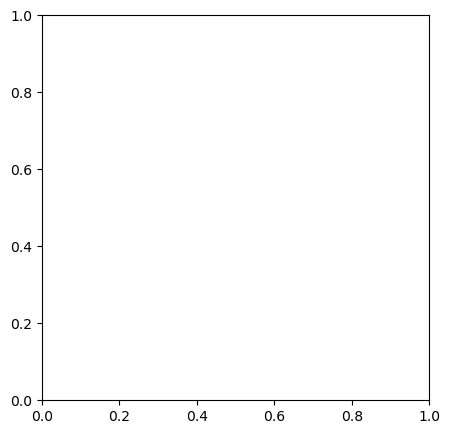

In [9]:
f, a = plot2(q_road1, q_road2, q_railways, q_river, q_districts, q_neighborhoods, variable="pi2")
f.savefig(f"{output_dir}/null_model_combined_alternative.png",
          dpi=300, facecolor="white", bbox_inches="tight")